In [1]:
# Imports
import torch
import torchvision
import torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader

import os
import random 
import matplotlib.pyplot as plt
from collections import defaultdict

# **1. Assembling the joint dataset**

In [2]:
transform = T.ToTensor() # Converts to Torch Tensor (C, H, W) so it can be later trained on

mnist = torchvision.datasets.MNIST(root='./data', download=True, transform=transform)  # Note this is only the 'training' data
svhn = torchvision.datasets.SVHN(root='./data', download=True, transform=transform)    # Note this is only the 'training' data

print(len(mnist))
print(len(svhn))

60000
73257


Get the indices per label of each dataset.

In [3]:
mnist_indices = defaultdict(list)
svhn_indices = defaultdict(list)

for i, label in enumerate(mnist.targets):
    mnist_indices[int(label)].append(i)

for i, label in enumerate(svhn.labels):
    svhn_indices[label].append(i)

print(mnist_indices[0])
print(svhn_indices[0])

[1, 21, 34, 37, 51, 56, 63, 68, 69, 75, 81, 88, 95, 108, 114, 118, 119, 121, 156, 169, 192, 206, 209, 210, 216, 229, 232, 234, 246, 249, 260, 283, 293, 296, 303, 320, 326, 359, 399, 427, 429, 435, 440, 451, 453, 458, 462, 464, 473, 489, 519, 524, 526, 527, 542, 577, 582, 596, 603, 612, 633, 639, 656, 662, 666, 667, 668, 669, 689, 702, 709, 712, 733, 743, 745, 776, 781, 787, 790, 818, 825, 849, 859, 860, 869, 872, 889, 903, 927, 943, 949, 952, 957, 965, 979, 984, 997, 1000, 1015, 1018, 1028, 1029, 1040, 1046, 1049, 1076, 1078, 1090, 1093, 1102, 1107, 1128, 1137, 1152, 1168, 1179, 1195, 1209, 1268, 1304, 1310, 1346, 1349, 1359, 1363, 1367, 1368, 1371, 1372, 1377, 1386, 1387, 1403, 1423, 1443, 1454, 1471, 1479, 1489, 1495, 1501, 1502, 1512, 1517, 1530, 1532, 1571, 1578, 1590, 1596, 1600, 1605, 1606, 1625, 1626, 1645, 1664, 1678, 1682, 1701, 1709, 1712, 1723, 1725, 1729, 1742, 1769, 1771, 1775, 1796, 1797, 1798, 1819, 1828, 1837, 1857, 1868, 1876, 1877, 1897, 1904, 1907, 1916, 1926, 1927, 

Calculating the number of pairs per number.

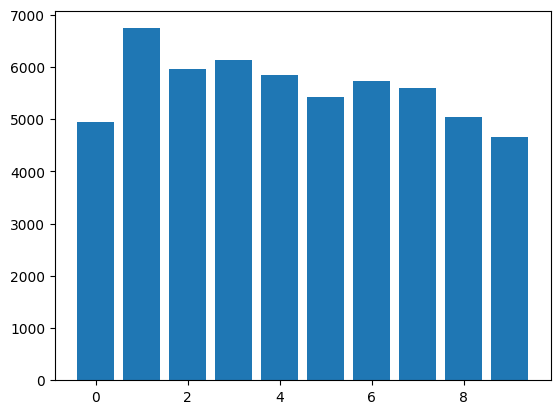

In [4]:
n_pairs = {
    digit: min(len(mnist_indices[digit]), len(svhn_indices[digit]))
    for digit in range(10)
}

plt.bar(n_pairs.keys(), n_pairs.values())
plt.show()

We decided not to balance the classes so far, since there are no big differences. Now we combine the datasets into tuples of indexes and their shared label.

In [5]:
pairs = []

for digit in range(10):
    mnist_idx = mnist_indices[digit].copy()
    svhn_idx = svhn_indices[digit].copy()

    # Shuffle to avoid bias
    random.shuffle(mnist_idx)
    random.shuffle(svhn_idx)

    n = n_pairs[digit]

    for mnist_idx, svhn_idx in zip(mnist_idx[:n], svhn_idx[:n]):
        pairs.append((mnist_idx, svhn_idx, digit))

print(pairs)

[(9067, 43635, 0), (56248, 6120, 0), (10747, 10922, 0), (42658, 23642, 0), (18113, 30156, 0), (2079, 37452, 0), (8515, 34405, 0), (31808, 57795, 0), (46041, 65611, 0), (29520, 35664, 0), (37663, 24577, 0), (669, 58231, 0), (33963, 37327, 0), (49459, 11632, 0), (39407, 30652, 0), (45596, 41668, 0), (3012, 12890, 0), (5074, 24362, 0), (53503, 10507, 0), (8885, 25967, 0), (10259, 14439, 0), (1916, 71079, 0), (16619, 9867, 0), (30618, 66914, 0), (46818, 5359, 0), (49111, 14484, 0), (51044, 1430, 0), (57645, 42097, 0), (51045, 50282, 0), (16485, 61114, 0), (47716, 53474, 0), (22440, 13691, 0), (56023, 43953, 0), (17349, 41561, 0), (15734, 71987, 0), (29471, 19372, 0), (21975, 25734, 0), (15442, 52064, 0), (55297, 70754, 0), (48268, 37823, 0), (15926, 61239, 0), (49872, 73157, 0), (50949, 3313, 0), (31297, 23137, 0), (32609, 72095, 0), (6615, 60946, 0), (10348, 65390, 0), (25567, 66041, 0), (39620, 45157, 0), (26073, 21428, 0), (81, 16085, 0), (15237, 54499, 0), (49949, 49080, 0), (46796, 57

Now we create a combained pytorch dataset with both images and their label.

In [6]:
class CombinedDataset(Dataset):
    def __init__(self, mnist, svhn, pairs):
        self.mnist = mnist
        self.svhn = svhn
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        mnist_idx, svhn_idx, label = self.pairs[idx]

        img_mnist, _ = self.mnist[mnist_idx]
        img_svhn, _ = self.svhn[svhn_idx]

        return img_mnist, img_svhn, label

Label: 0


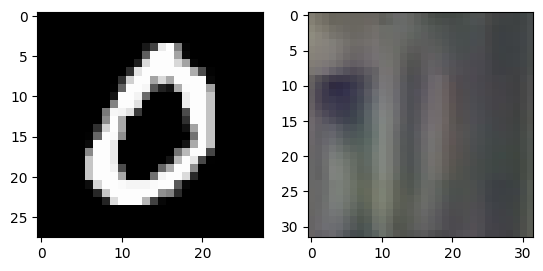

In [7]:
combined = CombinedDataset(mnist, svhn, pairs)

img_mnist, img_svhn, label = combined[1]
print('Label:', label)
plt.subplot(1, 2, 1)
plt.imshow(img_mnist.squeeze(), cmap = 'gray')
plt.subplot(1, 2, 2)
plt.imshow(img_svhn.permute(1,2,0))
plt.show()

In [8]:
print(img_svhn.shape, img_svhn.min(), img_svhn.max())
print(img_mnist.shape, img_mnist.min(), img_mnist.max())

torch.Size([3, 32, 32]) tensor(0.1686) tensor(0.5569)
torch.Size([1, 28, 28]) tensor(0.) tensor(1.)


In [ ]:
# Initializing the corresponding classes
from Nets import Encoder, Decoder, multiviewVAE
from architecture import (
    mnist_encoder_conv_stack,
    mnist_decoder_conv_stack,
    svhn_decoder_conv_stack,
    svhn_encoder_conv_stack,
    mnist_encoder_linear_stack,
    mnist_decoder_linear_stack,
    svhn_encoder_linear_stack,
    svhn_decoder_linear_stack
    )


latent_dim = 20 # Shared latent space
private_dim_svhn = 4 # Latent dim for SVHN
private_dim_mnist = 1 # Latent dim for MNIST

# Initializing encoder
encoder1 = Encoder(
    latent_dim=latent_dim, 
    private_dim=private_dim_mnist,
    conv_stack = mnist_encoder_conv_stack(),
    linear_stack= mnist_encoder_linear_stack(latent_dim, private_dim_mnist)
)
encoder2 = Encoder(
    latent_dim=latent_dim, 
    private_dim=private_dim_svhn, 
    conv_stack = svhn_encoder_conv_stack(),
    linear_stack= svhn_encoder_linear_stack(latent_dim,private_dim_svhn)
)

# Initializing decoders
# MNIST Decoder
decoder1 = Decoder(
    conv_stack=mnist_decoder_conv_stack(),
    linear_stack=mnist_decoder_linear_stack(latent_dim, private_dim_mnist),
    channels=256,
    height=1,
    width=1,
)

# SVHN Decoder
decoder2 = Decoder(
    conv_stack=svhn_decoder_conv_stack(),
    linear_stack=svhn_decoder_linear_stack(latent_dim, private_dim_svhn),
    channels=256,
    height=1,
    width=1,
)

# Initializing multi-viewVAE
vae = multiviewVAE(
    encoder1=encoder1,
    encoder2=encoder2,
    decoder1=decoder1,
    decoder2=decoder2,
    var_x1=0.08, # May be adjusted depending on if we prioritize KL or not, Lower values provide more importance to detail while reducing KL divergence influence
    var_x2=0.08, # A really low var_x value will completely discard the KL divergence, therefore, reducing generation performance
    private_dim_mnist=private_dim_mnist,
    private_dim_svhn=private_dim_svhn
)


In [10]:
# Train on GPU if possible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vae  = vae.to(device)

# Training Loop
dataloader = DataLoader(combined, batch_size=128, shuffle=True)

history = vae.train_loop(dataloader, lr=3e-4, epochs=30, device=device)

Epoch 1 | ELBO loss: -411.665 | LL: 831.315 | Align Loss: 0.317 | KL shared (s1/s2): 1.004/0.655 | KL private (p1/p2): 2.205/3.487
Epoch 2 | ELBO loss: -775.432 | LL: 1568.447 | Align Loss: 0.743 | KL shared (s1/s2): 1.663/0.610 | KL private (p1/p2): 3.472/10.352
Epoch 3 | ELBO loss: -854.791 | LL: 1740.445 | Align Loss: 2.810 | KL shared (s1/s2): 5.951/3.891 | KL private (p1/p2): 3.685/11.715
Epoch 4 | ELBO loss: -883.412 | LL: 1803.899 | Align Loss: 3.037 | KL shared (s1/s2): 8.771/6.559 | KL private (p1/p2): 3.749/11.922
Epoch 5 | ELBO loss: -902.038 | LL: 1843.090 | Align Loss: 2.677 | KL shared (s1/s2): 9.931/7.798 | KL private (p1/p2): 3.876/12.055
Epoch 6 | ELBO loss: -918.217 | LL: 1877.842 | Align Loss: 2.785 | KL shared (s1/s2): 10.967/8.791 | KL private (p1/p2): 4.018/12.062
Epoch 7 | ELBO loss: -928.379 | LL: 1899.267 | Align Loss: 2.874 | KL shared (s1/s2): 11.518/9.024 | KL private (p1/p2): 4.126/12.093
Epoch 8 | ELBO loss: -935.907 | LL: 1915.182 | Align Loss: 2.916 | KL

In [ ]:
# Saving model weights and architecture
os.makedirs("./checkpoints", exist_ok=True)
torch.save(vae, "./checkpoints/multiview_vae.pth")

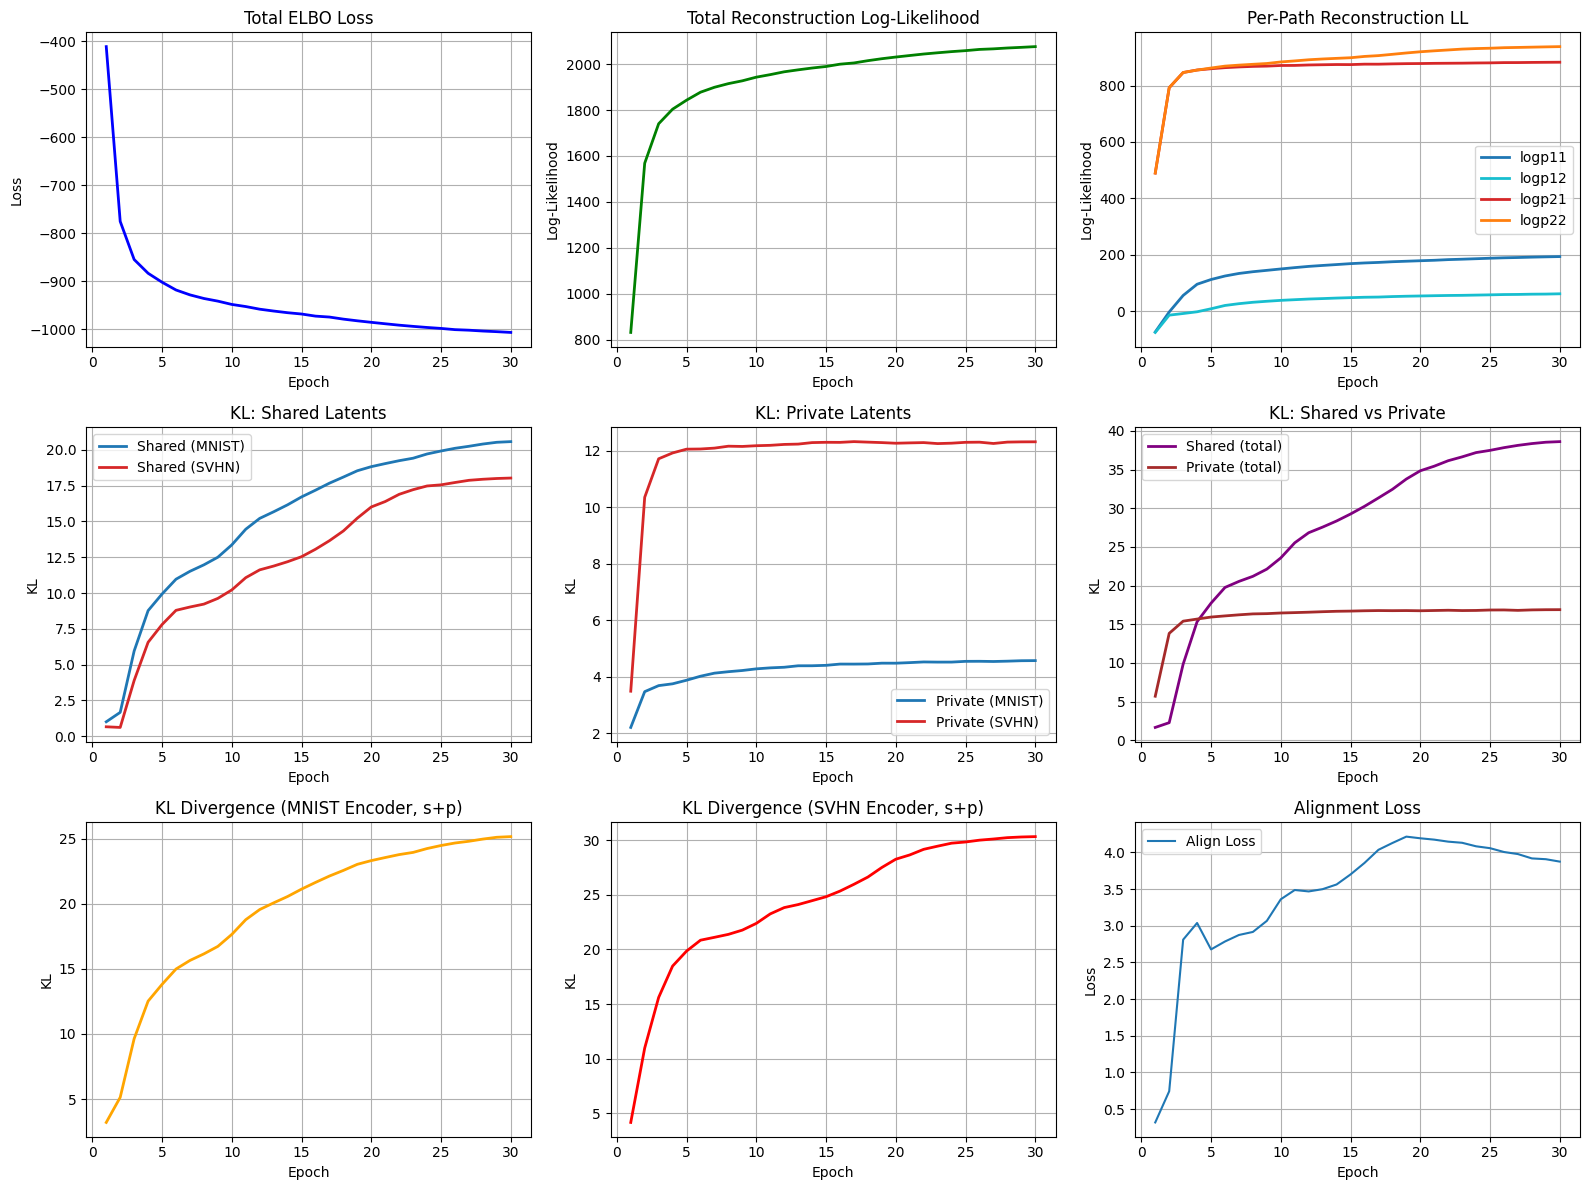

In [12]:
# Plotting training losses
epochs_range = range(1, len(history["elbo"]) + 1)

plt.figure(figsize=(16, 12))

# ELBO loss
plt.subplot(3, 3, 1)
plt.plot(epochs_range, history["elbo"], color="blue", linewidth=2)
plt.title("Total ELBO Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.grid(True)

# Total Reconstruction
plt.subplot(3, 3, 2)
plt.plot(epochs_range, history["rec"], color="green", linewidth=2)
plt.title("Total Reconstruction Log-Likelihood")
plt.xlabel("Epoch"); plt.ylabel("Log-Likelihood"); plt.grid(True)

# Log-likelihoods per path
plt.subplot(3, 3, 3)
for k, c in zip(["logp11", "logp12", "logp21", "logp22"], ["tab:blue", "tab:cyan", "tab:red", "tab:orange"]):
    plt.plot(epochs_range, history[k], label=k, color=c, linewidth=2)
plt.title("Per-Path Reconstruction LL")
plt.xlabel("Epoch"); plt.ylabel("Log-Likelihood"); plt.legend(); plt.grid(True)

# Shared KLs
plt.subplot(3, 3, 4)
plt.plot(epochs_range, history["kl_s1"], label="Shared (MNIST)", color="tab:blue", linewidth=2)
plt.plot(epochs_range, history["kl_s2"], label="Shared (SVHN)", color="tab:red", linewidth=2)
plt.title("KL: Shared Latents")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.legend(); plt.grid(True)

# Private KLs
plt.subplot(3, 3, 5)
plt.plot(epochs_range, history["kl_p1"], label="Private (MNIST)", color="tab:blue", linewidth=2)
plt.plot(epochs_range, history["kl_p2"], label="Private (SVHN)", color="tab:red", linewidth=2)
plt.title("KL: Private Latents")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.legend(); plt.grid(True)

# Shared vs private totals
plt.subplot(3, 3, 6)
plt.plot(epochs_range, history["kl_shared"], label="Shared (total)", color="purple", linewidth=2)
plt.plot(epochs_range, history["kl_private"], label="Private (total)", color="brown", linewidth=2)
plt.title("KL: Shared vs Private")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.legend(); plt.grid(True)

# KL Totals
plt.subplot(3, 3, 7)
plt.plot(epochs_range, history["kl1"], color="orange", linewidth=2)
plt.title("KL Divergence (MNIST Encoder, s+p)")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.grid(True)

plt.subplot(3, 3, 8)
plt.plot(epochs_range, history["kl2"], color="red", linewidth=2)
plt.title("KL Divergence (SVHN Encoder, s+p)")
plt.xlabel("Epoch"); plt.ylabel("KL"); plt.grid(True)

# Align Loss
plt.subplot(3,3,9)
plt.plot(epochs_range, history["align"], label="Align Loss")
plt.title("Alignment Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.grid(True)

plt.tight_layout()
plt.show()

Training was doing ok, it was converging. However, we trained a bit more with a slightly lower learning rate to gain a few margins. In result, the gained performance was minimal as expected, however, we saved this approach and continued to the next step.

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

vae = torch.load("./checkpoints/multiview_vae.pth", map_location=device, weights_only=False)
vae = vae.to(device)

additional_epochs = 20
history_cont = vae.train_loop(dataloader, lr=1e-4, epochs=additional_epochs, device=device)

torch.save(vae, "./checkpoints/multiview_vae_full_epoch50.pth")

Epoch 1 | ELBO loss: -1013.392 | LL: 2090.397 | Align Loss: 3.816 | KL shared (s1/s2): 20.812/18.182 | KL private (p1/p2): 4.610/12.377
Epoch 2 | ELBO loss: -1014.512 | LL: 2092.680 | Align Loss: 3.755 | KL shared (s1/s2): 20.916/18.223 | KL private (p1/p2): 4.622/12.386
Epoch 3 | ELBO loss: -1014.935 | LL: 2093.634 | Align Loss: 3.714 | KL shared (s1/s2): 20.964/18.360 | KL private (p1/p2): 4.633/12.379
Epoch 4 | ELBO loss: -1015.581 | LL: 2094.971 | Align Loss: 3.707 | KL shared (s1/s2): 21.000/18.365 | KL private (p1/p2): 4.632/12.395
Epoch 5 | ELBO loss: -1016.263 | LL: 2096.328 | Align Loss: 3.675 | KL shared (s1/s2): 21.077/18.300 | KL private (p1/p2): 4.641/12.434
Epoch 6 | ELBO loss: -1016.844 | LL: 2097.548 | Align Loss: 3.663 | KL shared (s1/s2): 21.116/18.336 | KL private (p1/p2): 4.641/12.440
Epoch 7 | ELBO loss: -1017.386 | LL: 2098.691 | Align Loss: 3.643 | KL shared (s1/s2): 21.150/18.378 | KL private (p1/p2): 4.642/12.463
Epoch 8 | ELBO loss: -1018.052 | LL: 2099.975 | 

: 